In [ ]:
import torch

x = torch.randn(3, 64, 64) # 더미데이터
T = 1000
betas = torch.linspace(0.0001, 0.02, T) # 하이퍼 파라미터. 0.0001 ~ 0.02 까지 T개로 균일하게 나눈값들

for t in range(T):
    beta = betas[t]
    eps = torch.randn_like(x) # 데이터와 동일한 모양으로 노이즈 생성
    x = torch.sqrt(1 - beta) * x + torch.sqrt(beta) * eps # 노이즈 추가

(64, 64, 3)
torch.Size([3, 64, 64])


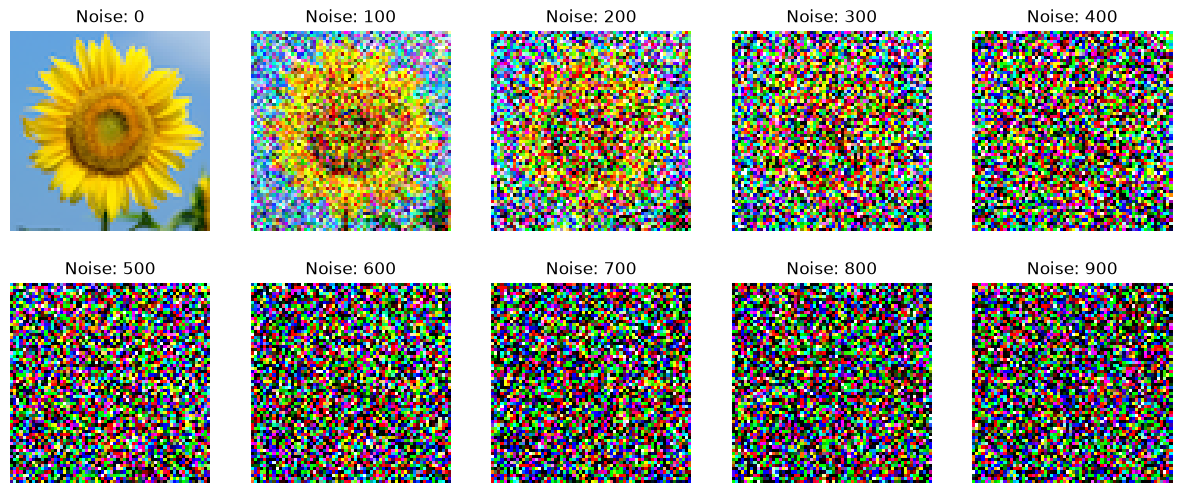

In [ ]:
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

# 이미지 불러오기
file_path = 'flower.png'
image = plt.imread(file_path)
print(image.shape)

# 이미지 전처리
preprocess = transforms.ToTensor()
x = preprocess(image)
print(x.shape)

def reverse_to_img(x):
    x = x * 255                         # 각 원소값을 원래 범위로 스케일링
    x = x.clamp(0, 255)                 # 각 원소의 값을 0 ~ 255 범위로 제한
    x = x.to(torch.uint8)               # 데이터 타입을 torch.uint8로 변환
    to_pil = transforms.ToPILImage()    # PIL 이미지 변환 전처리기
    return to_pil(x)

T = 1000
beta_start = 0.0001
beta_end = 0.02
betas = torch.linspace(beta_start, beta_end, T)
imgs = []

for t in range(T):
    if t % 100 == 0:
        img = reverse_to_img(x)
        imgs.append(img)

    beta = betas[t]
    eps = torch.randn_like(x)
    x = torch.sqrt(1 - beta) * x + torch.sqrt(beta) * eps # 노이즈 추가

plt.figure(figsize=(15, 6))
for i, img in enumerate(imgs[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f'Noise: {i * 100}')
    plt.axis('off')
plt.show()

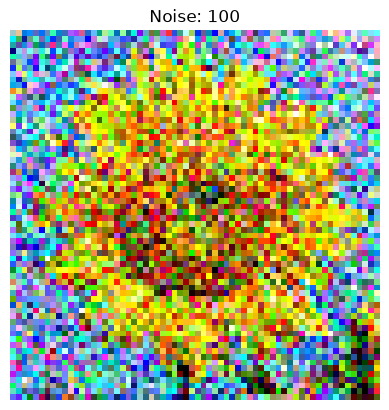

In [6]:
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

# 이미지 불러오기
file_path = 'flower.png'
image = plt.imread(file_path)

# 이미지 전처리
preprocess = transforms.ToTensor()
x = preprocess(image)

def reverse_to_img(x):
    x = x * 255                         # 각 원소값을 원래 범위로 스케일링
    x = x.clamp(0, 255)                 # 각 원소의 값을 0 ~ 255 범위로 제한
    x = x.to(torch.uint8)               # 데이터 타입을 torch.uint8로 변환
    to_pil = transforms.ToPILImage()    # PIL 이미지 변환 전처리기
    return to_pil(x)

T = 1000
beta_start = 0.0001
beta_end = 0.02
betas = torch.linspace(beta_start, beta_end, T)

# 노이즈를 반복문을 통해서 추가하는게 아니라, 누적곱을 통해 한번에 처리
def add_noise(x_0, t, betas):
    T = len(betas)
    assert t >= 1 and t <= T

    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0) # 누적곱. [1, 2, 3, 4] -> [1, 2, 6, 24]
    t_idx = t - 1
    alpha_bar = alpha_bars[t_idx]

    eps = torch.randn_like(x_0)
    x_t = torch.sqrt(alpha_bar) * x_0 + torch.sqrt(1 - alpha_bar) * eps

    return x_t 

t = 100 # t 100일때의 노이즈
x_t = add_noise(x, t, betas)

img = reverse_to_img(x_t)
plt.imshow(img)
plt.title(f'Noise: {t}')
plt.axis('off')
plt.show()